In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk2-task2-salmon.ipynb")

# Task 2: Wrangling Alaska salmon catch data 

## Instructions 

- First, update the following cell to have a link to *your* Homework 2 GitHub repository:

[Monique's GitHub link](https://github.com/moniqueallyson/eds220-hwk2.git)


- Review the [complete rubric for this task](https://docs.google.com/document/d/1x0BoU6IH4cnOR1-n7i9CYQ9wUC37yDpYlQ4j6rCfcsU/edit?tab=t.0) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- **Every code cell should have a comment.** Err on the side of commenting too much for now. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.

## Acknowledgments

This exercise is based on the [Cleaning and Wrangling Data in R lesson by the NCEAS Learning Hub](https://learning.nceas.ucsb.edu/2023-06-delta/session_11.html).


> Halina Do-Linh, Carmen Galaz García, Matthew B. Jones, Camila Vargas Poulsen. 2023. Open Science Synthesis training Week 1. NCEAS Learning Hub & Delta Stewardship Council.


## About the data

In this task you will use simplified data from the Alaska Department of Fish & Game containing commercial salmon catch data from 1878 to 1997. The original data can be accessed from the KNB repository:

> [Mike Byerly. (2016). Alaska commercial salmon catches by management region (1886-1997).](https://knb.ecoinformatics.org/view/df35b.304.2) Gulf of Alaska Data Portal. df35b.304.2.

The simplified dataset is in CSV format in the homework repository and has the following columns:

| Column | Description |
| ------ | ----------- | 
| Region | Region code |
| Year | Year fish were caught |
| notesRegCode | Notes and comments |
| Species | Species of salmon caught |
| Catch | Commercial catches of salmon species (in thousands of fish) |

## COMPLETE WORKFLOW

You will use the next code cell to complete the last exercise in the task. Leave it blank for now. 

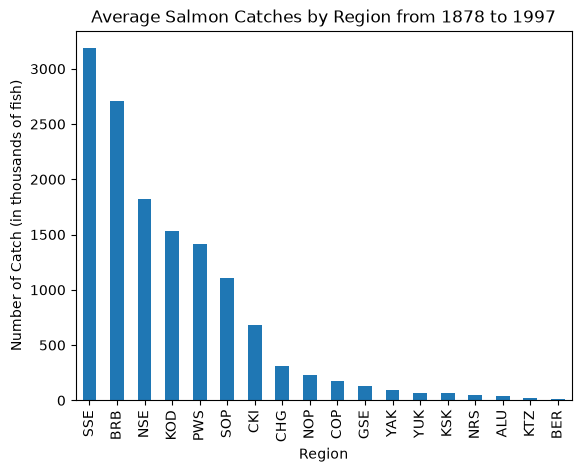

In [23]:
import pandas as pd

# Final Code

# Read in Salmon data
salmon_region = (
    pd.read_csv('data/salmon_data.csv')
    .assign(
    # Assign updated integer Catch column to a dataframe
      Catch=lambda df: df['Catch']
          .replace('I', '1')
          .astype(int))
    # Calculate the mean of Catch values by Region 
    .groupby('Region')['Catch']
    .mean()
    # Sort descending order
    .sort_values(ascending=False)
    # Display bar chart
    .plot(kind='bar',
      title='Average Salmon Catches by Region from 1878 to 1997',
      xlabel='Region',
      ylabel='Number of Catch (in thousands of fish)'))


## 1

a. Use this code cell to import the data from the `salmon_data.csv` as `catch_data`. Look at the head of the data frame. 

<!-- BEGIN QUESTION -->



In [11]:
# a. Read in library and data
import pandas as pd

# Read in salmon data
catch_data = pd.read_csv('data/salmon_data.csv')
catch_data.head()

,Region,Year,notesRegCode,Species,Catch
0,SSE,1886,NaN,Chinook,0
1,SSE,1887,NaN,Chinook,0
2,SSE,1888,NaN,Chinook,0
3,SSE,1889,NaN,Chinook,0
4,SSE,1890,NaN,Chinook,0


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use this code cell to make some other preliminary data exploration of your choosing.

In [12]:
# b. Data Exploration

# Display basic data information
catch_data.info()
# Give number of unique values in columns
catch_data.nunique()

<class 'pandas.DataFrame'>
RangeIndex: 8540 entries, 0 to 8539
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Region        8540 non-null   str  
 1   Year          8540 non-null   int64
 2   notesRegCode  1415 non-null   str  
 3   Species       8540 non-null   str  
 4   Catch         8540 non-null   str  
dtypes: int64(1), str(4)
memory usage: 333.7 KB


Region            18
Year             120
notesRegCode      29
Species            5
Catch           1879
dtype: int64

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Use this markdown cell to explain why you decided to do the exploration in b. and what information you obtained from doing it.

- I chose to use `.info()` since this will give the amount of columns and their names along with their `Dtype`, as well as the number of rows in the dataframe. The information that was obtained was the shape of the dataframe being (8540, 4) with the names of the columns being: Region, Year, Species, notesRegCode (though this has been droped and won't be seen), and Catch. I also chose to use `nunique()` to show the variation of values per column.

<!-- END QUESTION -->

## 2
In the next cell:

a. Store the unique values of the `notesRegCode` column in the `notes_unique` variable. 

In [13]:
# Show unique entries in the notesRegCode column
notes_unique = catch_data['notesRegCode'].unique()

print(notes_unique)

<StringArray>
[                                                                                   nan,
                                                             'Includes Yakutat catches',
                                             'Yakutat catch included in No SE AK catch',
                                   'Estimated from canned production, probably sockeye',
                                                                           'No fishery',
                                'Bering River catches included in Copper River catches',
                                 'Includes Bering River catches; estimated from canned',
                                                        'Includes Bering River catches',
                                 'Coho and pink catch estimated from canned production',
                            'Includes Bering River; coho and pink estimated fro canned',
                                                     'Pink catch estimated from canned',
       

In [6]:
grader.check("q2a")

q2a results: All test cases passed!

b. Update the data frame so it doesn't include the `notesRegCode` column. Verify the column is no longer in the data frame.

In [14]:
# Drop notesRegCode column from the dataframe
catch_data = catch_data.drop(columns='notesRegCode')

In [8]:
# Display first few rows to verify the column notesRegCode was dropped
catch_data.head()

,Region,Year,Species,Catch
0,SSE,1886,Chinook,0
1,SSE,1887,Chinook,0
2,SSE,1888,Chinook,0
3,SSE,1889,Chinook,0
4,SSE,1890,Chinook,0


In [9]:
grader.check("q2b")

q2b results: All test cases passed!

<!-- BEGIN QUESTION -->

## 3
Does each column have the expected data type? Use this code cell to obtain this information and write your answer in the next markdown cell.


In [15]:
# Display the data types for each column
print(catch_data.dtypes)

Region       str
Year       int64
Species      str
Catch        str
dtype: object


For the columns `Region` through `Species`, the dtypes are to be expected, except for the column `Catch` since it is categorized as a string depsite the entries being majority numbers, or the expected `int64`.

<!-- END QUESTION -->

## 4 
The following cell shows a first attempt at updating the `Catch` column to be of data type `int64` instead of `object`. Converting from one data type to another is often called **casting**. 

To do it we use the [`astype()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.astype.html) method for `pandas.Series`. The `astype()` method does not modify the `pandas.Series` in place.

Run the next cell and read the end of the error message closely.

In [16]:
# Create an error due to the dtype of Catch
catch_data['Catch'].astype('int64')

ValueError: invalid literal for int() with base 10: 'I'

## 5 

The previous error tells us there is a value 'I' (as in the letter 'I') that could not be converted to integer type. It turns out the original data set was created from a PDF which was automatically converted into a CSV file and this 'I' value should be 1.

In the next cell find the row(s) causing this issue. Show the filtered row(s) as the output. Store your answer in the `catch_I` variable. `catch_I` should have one observation and contain the following columns: Region, Year, Species, Catch. It should contain the original index number in order to pass the test. 

In [17]:
# Display dataframe with Catch starting with 'I'

catch_I = catch_data[catch_data['Catch'].str.startswith('I')]
catch_I

,Region,Year,Species,Catch
400,GSE,1955,Chinook,I


In [13]:
grader.check("q5")

q5 results: All test cases passed!

## 6
In the next cell:

1. Update the value of I to 1.
2. Access the row you updated to verify the value was changed and store this single row in the `catch_1` variable. 

<!-- BEGIN QUESTION -->



In [18]:
# Update the value in the 400th row in the Catch column from I to 1
catch_1 = catch_data.at[400,'Catch'] = "1"

# Print catch_1
catch_1

'1'

In [19]:
# Verify catch column no longer has I 
catch_data[catch_data['Catch'].str.startswith('I')]

,Region,Year,Species,Catch


In [16]:
# Verify by location
catch_data.loc[400]

Region         GSE
Year          1955
Species    Chinook
Catch            1
Name: 400, dtype: object

<!-- END QUESTION -->

## 7
In the next cell:

1. Update the `Catch` column in `catch_data` to be of type `int64`.
2. Confirm you have updated the data type. Store the type of the `Catch` column in the `catch_column_type` variable.

In [20]:
# Update the Catch column to int64 from string
catch_data['Catch'] = catch_data['Catch'].astype(int)

# Verify the column type of Catch
catch_column_type = catch_data['Catch'].dtype
catch_column_type

dtype('int64')

In [ ]:
grader.check("q7")

<!-- BEGIN QUESTION -->

## 8
Create a data frame with the average salmon catch per region. HINT: use `groupby()`. Store your data frame in a new variable called `avg_region`


In [21]:
# Create new dataframe with the average of salmon caught by region
avg_region = catch_data.groupby('Region')['Catch'].mean()
avg_region

Region
ALU      40.383908
BER      16.372549
BRB    2709.796491
CHG     315.487273
CKI     683.571429
COP     179.223404
GSE     133.841463
KOD    1528.350000
KSK      67.642353
KTZ      18.836145
NOP     229.493478
NRS      51.502703
NSE    1825.020870
PWS    1419.236697
SOP    1110.942222
SSE    3184.660714
YAK      91.922917
YUK      68.645570
Name: Catch, dtype: float64

In [ ]:
grader.check("q8")

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 9 

Use the data frame you created in 8 to make a bar graph of the estimated average salmon catches by region from 1878 to 1997. The bars in the graph should be ordered by magnitude (increasing or decreasing is ok). Add a title to your graph and update the axes labels if needed (check the units for the salmon catch). 

<Axes: title={'center': 'Average Salmon Catches by Region from 1878 to 1997'}, xlabel='Region', ylabel='Number of Catch (in thousands of fish)'>

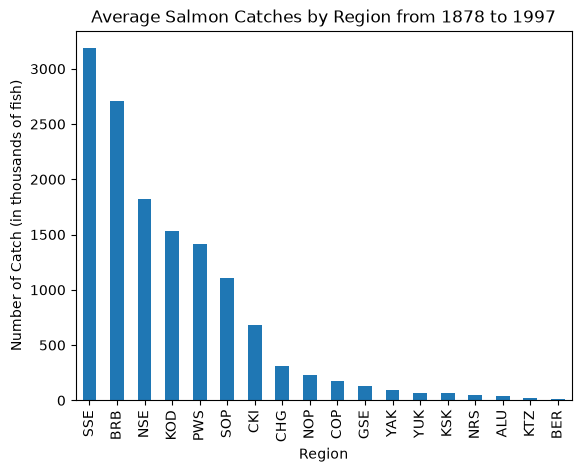

In [24]:
# Create bar plot by descending order of average salmon catch by region
avg_region.sort_values(ascending=False).plot(kind='bar',
                                                        title='Average Salmon Catches by Region from 1878 to 1997',
                                                        xlabel='Region',
                                                        ylabel='Number of Catch (in thousands of fish)')

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 10

Write a brief description with key takeaways from the plot. Your answer should use the complete names for the management areas instead of their codes. You can find what each code stands for in the [original data repository](https://knb.ecoinformatics.org/view/df35b.304.2#df35b.303.1).

- The highest catch shown was in Southern Southeast Alaska (SSE) with a number of 3000 (thousands in fish), while the second highest at aproximately 2700 (thousands in fish) in the Bristol Bay Management Areas (BRB). The lowest in catch close to 16 (thousands in fish) in Bering River Subarea (BER). Lastly, the highest catches are concentrated in one-third of the regions, with the remaining twelve are below the 500 (thousands in fish) threshold.

<!-- END QUESTION -->

## 11

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the graph. The *only* output of this cell should be the graph you produced in the previous exercise. Further guidance on what to include in this final workflow is in the [assignment rubric](https://docs.google.com/document/d/1x0BoU6IH4cnOR1-n7i9CYQ9wUC37yDpYlQ4j6rCfcsU/edit?tab=t.0).

---

To double-check your work, the cell below will rerun all of the autograder tests.

In [ ]:
grader.check_all()